<div style='background-color: #fff7f7; border: 3px solid Red;'>
    <font size="+1" color="Red">
        <b>Please comment and upvote if you like this work!</b>
    </font>
</div>
<div style='background-color: #fff7f7; border: 3px solid Blue;'>
    <font size="+1" color="Red">
        <b>Take a look at the other notebooks in my profile ->
        <a href="https://www.kaggle.com/killa92/code">  Kaggle Notebooks </a></b>
    </font>
</div>    
<div style='background-color: #fff7f7; border: 3px solid yellow;'>
    <font size="+1" color="Red">
        <b><span style='color: green;'>Let's Support Each Other!!</span></b>
    </font>
</div>

<div style='background-color: #fff7f7; border: 2px solid '>
    <font size="+2" color="blue" ><b>🗂️1. Custom Datasets and DataLoaders 🗂️</b></font>
</div>

In [1]:
import os, torch, shutil, numpy as np
from glob import glob; from PIL import Image
from torch.utils.data import random_split, Dataset, DataLoader
from torchvision import transforms as T
torch.manual_seed(2024)

class CustomDataset(Dataset):
    
    def __init__(self, root, data_type = None, transformations = None):
        
        self.transformations = transformations
        self.data_type       = data_type
        self.im_paths = glob(f"{root}/{data_type}/*/*.jpg") if data_type == "train" else glob(f"{root}/{data_type}/images/*.jpg")
        
        if self.data_type == "train": self.get_info()
        
    def get_info(self):

        self.cls_names, self.cls_counts, count, data_count = {}, {}, 0, 0
        for idx, im_path in enumerate(self.im_paths):
            class_name = self.get_class(im_path)
            if class_name not in self.cls_names: self.cls_names[class_name] = count; self.cls_counts[class_name] = 1; count += 1
            else: self.cls_counts[class_name] += 1
        
    def get_class(self, path): return os.path.dirname(path).split("/")[-1]
    
    def __len__(self): return len(self.im_paths)

    def __getitem__(self, idx):
        
        im_path = self.im_paths[idx]
        im = Image.open(im_path).convert("RGB")
        gt = self.cls_names[self.get_class(im_path)] if self.data_type =="train" else im_path
        
        if self.transformations is not None: im = self.transformations(im)
        
        return im, gt
    
def get_dls(root, transformations, bs, split = [0.9, 0.05, 0.05], ns = 4):
    
    dataset = CustomDataset(root = root, data_type = "train", transformations = transformations)    
    ts_ds   = CustomDataset(root = root, data_type = "test", transformations = transformations)    
    
    total_len = len(dataset)
    tr_len = int(total_len * split[0])
    vl_len = total_len - tr_len
    ts_len = total_len - (tr_len + vl_len)
    
    tr_ds, vl_ds = random_split(dataset = dataset, lengths = [tr_len, vl_len])
    
    tr_dl, val_dl, ts_dl = DataLoader(tr_ds, batch_size = bs, shuffle = True, num_workers = ns), DataLoader(vl_ds, batch_size = bs, shuffle = False, num_workers = ns), DataLoader(ts_ds, batch_size = 1, shuffle = False, num_workers = ns)
    
    return tr_dl, val_dl, ts_dl, dataset.cls_names

root = "/kaggle/input/exam-cheating-dataset/ExamCheatingDataset"
mean, std, im_size = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225], 64
tfs = T.Compose([T.Resize((im_size, im_size)), T.ToTensor(), T.Normalize(mean = mean, std = std)])
tr_dl, val_dl, ts_dl, classes = get_dls(root = root, transformations = tfs, bs = 16)

print(len(tr_dl)); print(len(val_dl)); print(len(ts_dl)); print(classes)

85
10
496
{'giving object': 0, 'giving code': 1, 'normal act': 2, 'cheating': 3, 'looking friend': 4}


<ipython-input-2-576a5cf773de>:46: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cls_names, rotation=60)


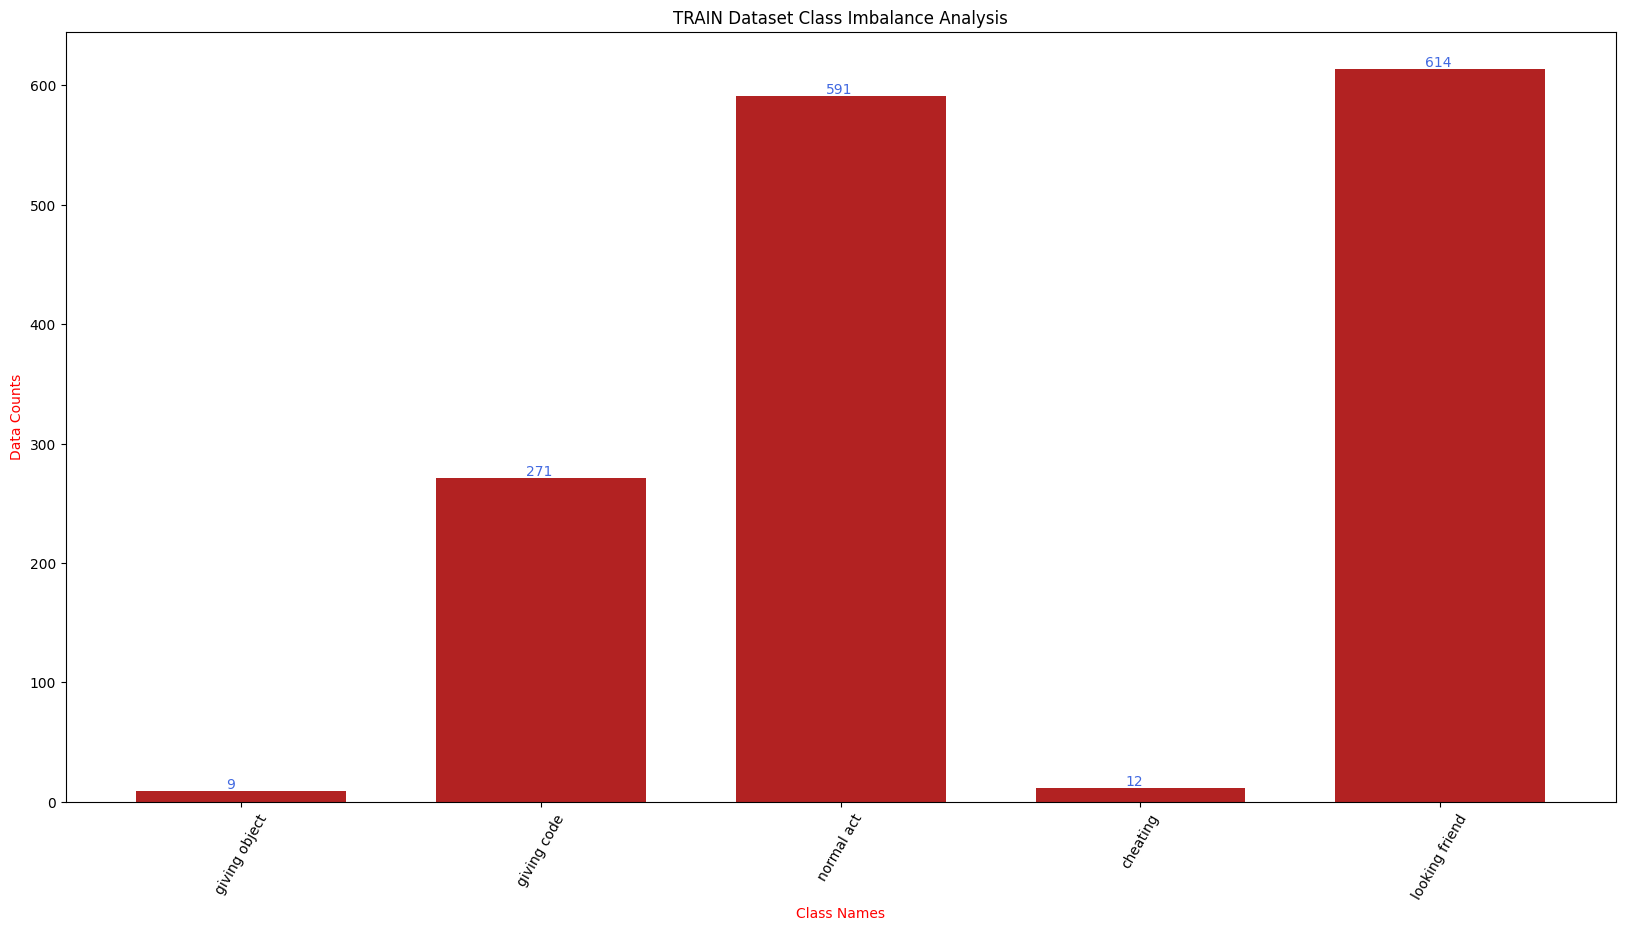

In [2]:
import random
import numpy as np
from matplotlib import pyplot as plt
import torchvision.transforms as T

class DataAnalyzerAndVisualizer:
    def __init__(self, root, data_type, transformations, cls_names=None):
        self.root = root
        self.data_type = data_type
        self.transformations = transformations
        self.cls_names = cls_names
        self.dataset = self.load_dataset()
        self.cls_counts = self.dataset.cls_counts

    def load_dataset(self):
        # Assumes a CustomDataset class exists.
        return CustomDataset(root=self.root, data_type = self.data_type, transformations=self.transformations)

    @staticmethod
    def tensor_to_image(tensor, t_type="rgb"):
        gray_transforms = T.Compose([
            T.Normalize(mean=[0.], std=[1 / 0.5]),
            T.Normalize(mean=[-0.5], std=[1])
        ])
        rgb_transforms = T.Compose([
            T.Normalize(mean=[0., 0., 0.], std=[1 / 0.229, 1 / 0.224, 1 / 0.225]),
            T.Normalize(mean=[-0.485, -0.456, -0.406], std=[1., 1., 1.])
        ])

        inv_transforms = gray_transforms if t_type == "gray" else rgb_transforms
        if t_type == "gray":
            return (inv_transforms(tensor) * 255).detach().squeeze().cpu().numpy().astype(np.uint8)
        return (inv_transforms(tensor) * 255).detach().cpu().permute(1, 2, 0).numpy().astype(np.uint8)

    def analyze_class_distribution(self):
        cls_counts = self.cls_counts
        cls_names = list(cls_counts.keys())
        counts = list(cls_counts.values())

        width, text_width, text_height = 0.7, 0.05, 2
        indices = np.arange(len(counts))

        fig, ax = plt.subplots(figsize=(20, 10))
        ax.bar(indices, counts, width, color="firebrick")
        ax.set_xlabel("Class Names", color="red")
        ax.set_xticklabels(cls_names, rotation=60)
        ax.set(xticks=indices, xticklabels=cls_names)
        ax.set_ylabel("Data Counts", color="red")
        ax.set_title(f"{self.data_type.upper()} Dataset Class Imbalance Analysis")

        for i, v in enumerate(counts):
            ax.text(i - text_width, v + text_height, str(v), color="royalblue")

        plt.show()

    def visualize_data(self, n_samples, rows, cmap=None):
        assert cmap in ["rgb", "gray", None], "Specify 'rgb' or 'gray' for the image type!"
        cmap = "viridis" if cmap == "rgb" else cmap

        plt.figure(figsize=(20, 10))
        random_indices = [random.randint(0, len(self.dataset) - 1) for _ in range(n_samples)]

        for idx, index in enumerate(random_indices):
            image, label = self.dataset[index]
            plt.subplot(rows, n_samples // rows, idx + 1)

            if cmap:
                plt.imshow(self.tensor_to_image(image, cmap), cmap=cmap)
            else:
                plt.imshow(self.tensor_to_image(image))

            plt.axis('off')
            if self.cls_names is not None:
                plt.title(f"GT -> {self.cls_names[int(label)]}")
            else:
                plt.title(f"GT -> {label}")

        plt.show()

train_analyzer_visualizer = DataAnalyzerAndVisualizer(root=root, data_type = "train", transformations=tfs, cls_names=list(classes.keys()))
train_analyzer_visualizer.analyze_class_distribution()

<div style='background-color: #fff7f7; border: 2px solid '>
    <font size="+2" color="blue" ><b>📊 3. Data Visualization 📊</b></font>
</div>

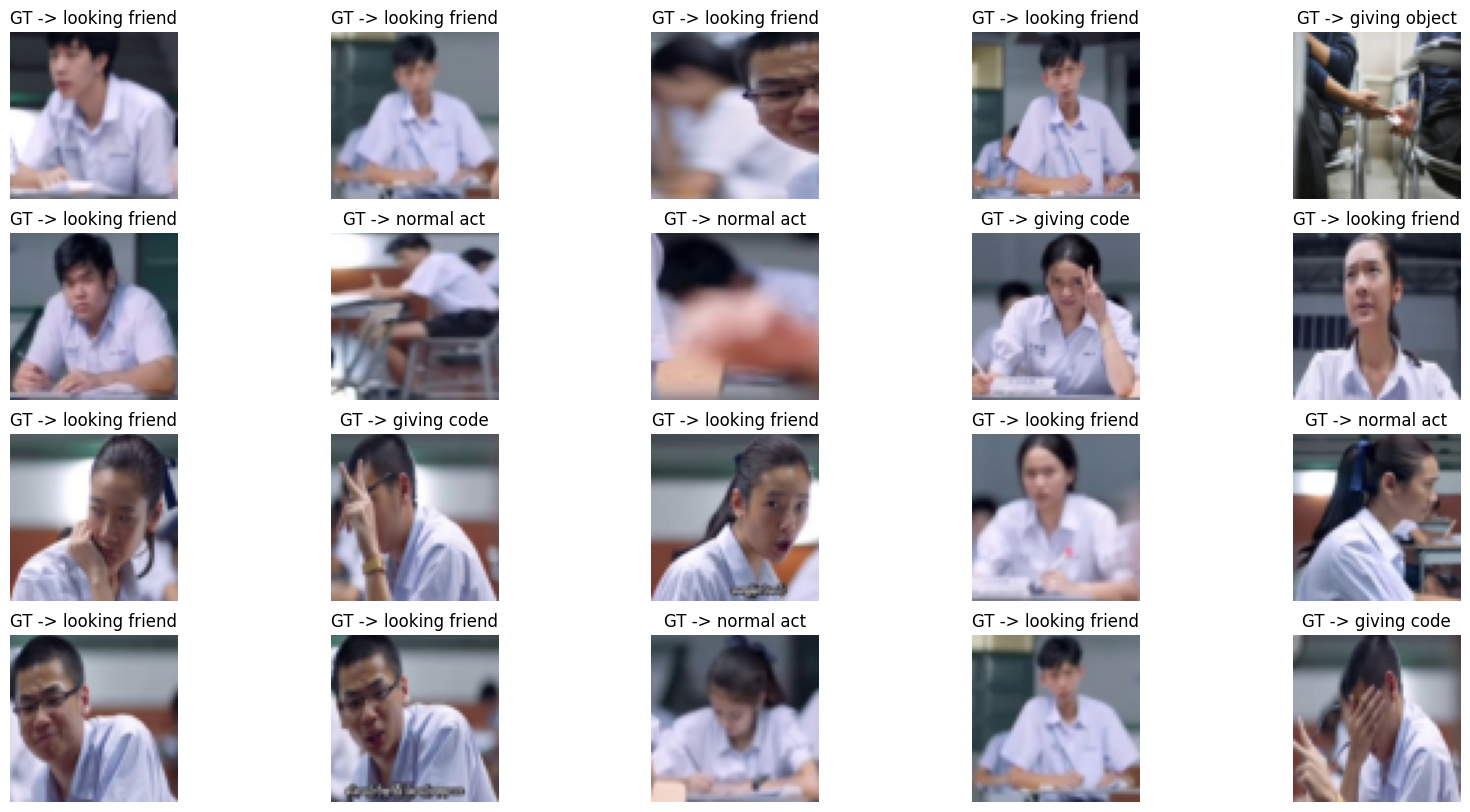

In [3]:
train_analyzer_visualizer.visualize_data(n_samples=20, rows=4, cmap="rgb")

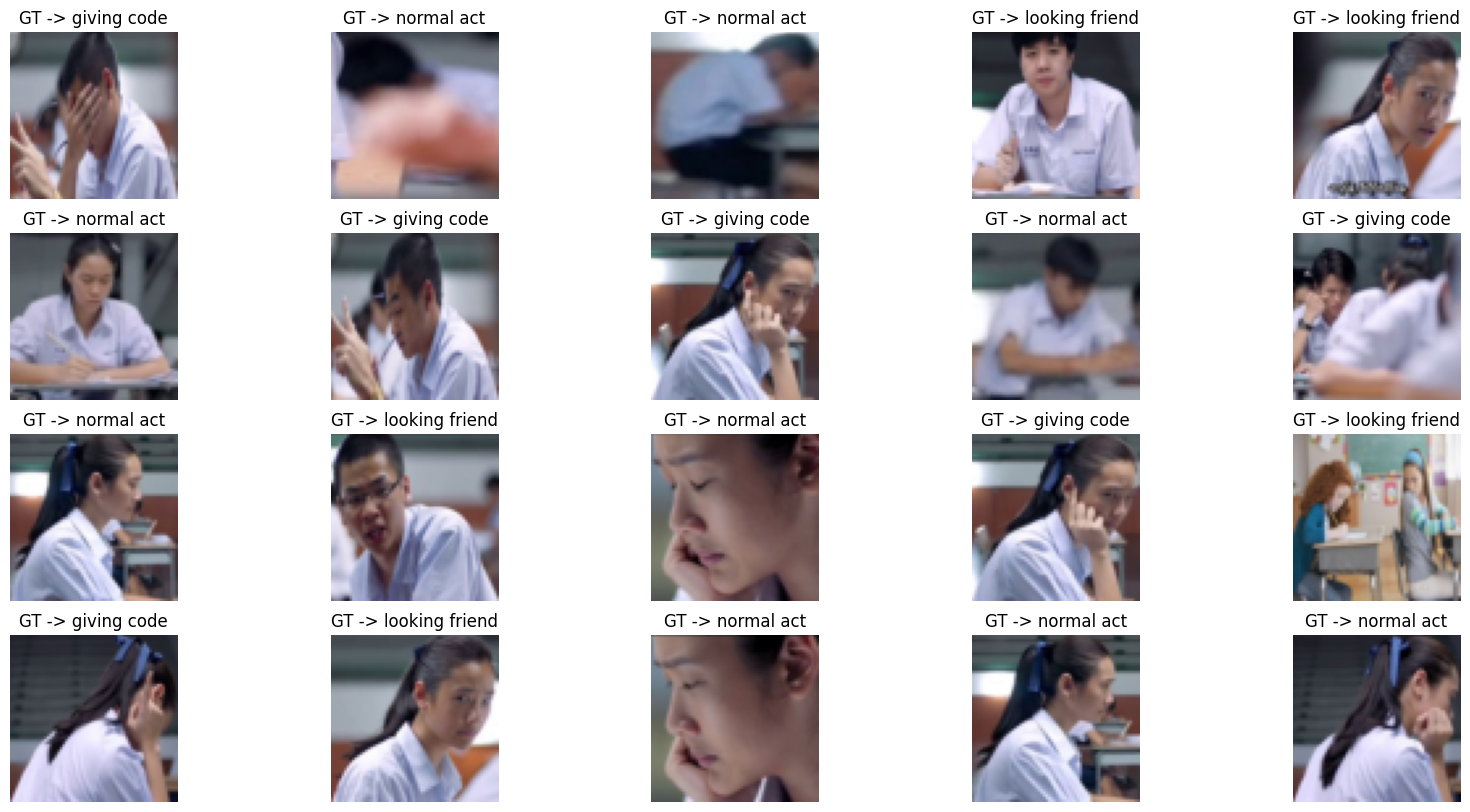

In [4]:
train_analyzer_visualizer.visualize_data(n_samples=20, rows=4, cmap="rgb")

<div style='background-color: #fff7f7; border: 2px solid '>
    <font size="+2" color="blue" ><b>✨ 4. AI Model Train and Validation ✨</b></font>
</div>

In [5]:
import os, torchmetrics
import timm
from tqdm import tqdm

class TrainValidation:
    def __init__(self, model_name, classes, tr_dl, val_dl, device, save_dir="saved_models", save_prefix="model", lr=3e-4, epochs=50, patience=5, threshold=0.01):
        self.model_name = model_name
        self.classes = classes
        self.tr_dl = tr_dl
        self.val_dl = val_dl
        self.save_dir = save_dir
        self.save_prefix = save_prefix
        self.lr = lr
        self.epochs = epochs
        self.patience = patience
        self.threshold = threshold

        self.device = device
        self.model = timm.create_model(model_name, pretrained=True, num_classes=len(classes)).to(self.device)
        self.loss_fn = torch.nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        self.f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(classes)).to(self.device)

        os.makedirs(save_dir, exist_ok=True)

        self.best_loss = float("inf")
        self.best_acc = 0
        self.not_improved = 0

        self.tr_losses, self.val_losses = [], []
        self.tr_accs, self.val_accs = [], []
        self.tr_f1s, self.val_f1s = [], []

    @staticmethod
    def to_device(batch, device):
        ims, gts = batch
        return ims.to(device), gts.to(device)

    def train_epoch(self):
        self.model.train()
        train_loss, train_acc = 0.0, 0.0
        self.f1_metric.reset()

        for batch in tqdm(self.tr_dl, desc="Training"):            
            
            ims, gts = TrainValidation.to_device(batch = batch, device = self.device)
            # ims, gts = self.to_device((ims, gts))
            
            # Forward pass
            preds = self.model(ims)
            loss = self.loss_fn(preds, gts)
            
            # Backward pass
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            
            # Update metrics
            train_loss += loss.item()
            train_acc += (torch.argmax(preds, dim=1) == gts).sum().item()
            self.f1_metric.update(preds, gts)

        train_loss /= len(self.tr_dl)
        train_acc /= len(self.tr_dl.dataset)
        train_f1 = self.f1_metric.compute().item()
        
        self.tr_losses.append(train_loss)
        self.tr_accs.append(train_acc)
        self.tr_f1s.append(train_f1)

        return train_loss, train_acc, train_f1

    def validate_epoch(self):
        self.model.eval()
        val_loss, val_acc = 0.0, 0.0
        self.f1_metric.reset()

        with torch.no_grad():
            for batch in tqdm(self.val_dl, desc="Validation"):
                # ims, gts = self.to_device((ims, gts))
                ims, gts = TrainValidation.to_device(batch, device = self.device)
                preds = self.model(ims)
                loss = self.loss_fn(preds, gts)

                # Update metrics
                val_loss += loss.item()
                val_acc += (torch.argmax(preds, dim=1) == gts).sum().item()
                self.f1_metric.update(preds, gts)

        val_loss /= len(self.val_dl)
        val_acc /= len(self.val_dl.dataset)
        val_f1 = self.f1_metric.compute().item()

        self.val_losses.append(val_loss)
        self.val_accs.append(val_acc)
        self.val_f1s.append(val_f1)

        return val_loss, val_acc, val_f1

    def save_best_model(self, val_f1, val_loss):
        if val_f1 > self.best_acc + self.threshold:
            self.best_acc = val_f1
            self.best_loss = val_loss
            save_path = os.path.join(self.save_dir, f"{self.save_prefix}_best_model.pth")
            torch.save(self.model.state_dict(), save_path)
            print(f"Best model saved with F1-Score: {self.best_acc:.3f}")
            self.not_improved = 0
        else:
            self.not_improved += 1
            print(f"No improvement for {self.not_improved} epoch(s).")

    def verbose(self, epoch, metric1, metric2, metric3, process = "train"):

        print(f"{epoch + 1}-epoch {process} process is completed!\n")
        print(f"{epoch + 1}-epoch {process} loss          -> {metric1:.3f}")
        print(f"{epoch + 1}-epoch {process} accuracy      -> {metric2:.3f}")
        print(f"{epoch + 1}-epoch {process} f1-score      -> {metric3:.3f}\n")
    
    def run(self):
        print("Start training...")

        for epoch in range(self.epochs):
            print(f"\nEpoch {epoch + 1}/{self.epochs}:\n")

            train_loss, train_acc, train_f1 = self.train_epoch()
            self.verbose(epoch, train_loss, train_acc, train_f1, process = "train")

            val_loss, val_acc, val_f1 = self.validate_epoch()
            self.verbose(epoch, val_loss, val_acc, val_f1, process = "validation")            

            self.save_best_model(val_f1, val_loss)

            if self.not_improved >= self.patience:
                print("Early stopping triggered.")
                break

model_name   = "rexnet_150"
save_prefix  = "exam_cheating"
save_dir     = "saved_models"
device       = "cuda" if torch.cuda.is_available() else "cpu"

trainer = TrainValidation(model_name = model_name, device = device, save_prefix = save_prefix, classes = classes, tr_dl = tr_dl, val_dl = val_dl)
trainer.run()

model.safetensors:   0%|          | 0.00/39.2M [00:00<?, ?B/s]

Start training...

Epoch 1/50:



Training: 100%|██████████| 85/85 [00:06<00:00, 13.73it/s]


1-epoch train process is completed!

1-epoch train loss          -> 1.293
1-epoch train accuracy      -> 0.800
1-epoch train f1-score      -> 0.800



Validation: 100%|██████████| 10/10 [00:00<00:00, 19.55it/s]


...

9-epoch validation process is completed!

9-epoch validation loss          -> 0.178
9-epoch validation accuracy      -> 0.953
9-epoch validation f1-score      -> 0.953

No improvement for 4 epoch(s).

Epoch 10/50:



Training: 100%|██████████| 85/85 [00:04<00:00, 18.69it/s]


10-epoch train process is completed!

10-epoch train loss          -> 0.082
10-epoch train accuracy      -> 0.987
10-epoch train f1-score      -> 0.987



Validation: 100%|██████████| 10/10 [00:00<00:00, 24.77it/s]

10-epoch validation process is completed!

10-epoch validation loss          -> 0.133
10-epoch validation accuracy      -> 0.967
10-epoch validation f1-score      -> 0.967

No improvement for 5 epoch(s).
Early stopping triggered.


<div style='background-color: #fff7f7; border: 2px solid '>
    <font size="+2" color="blue" ><b>😍 5. Learning Curves 😍</b></font>
</div>

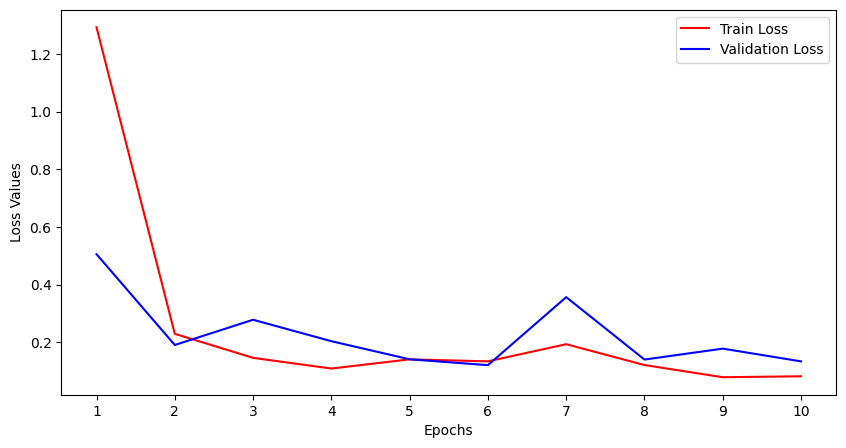

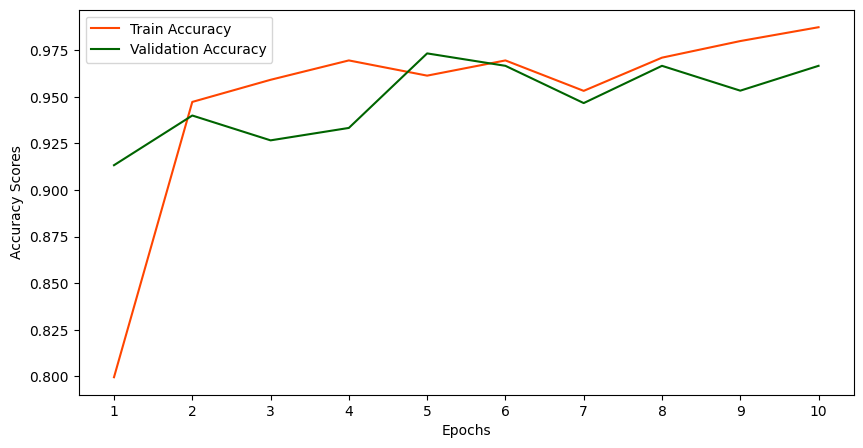

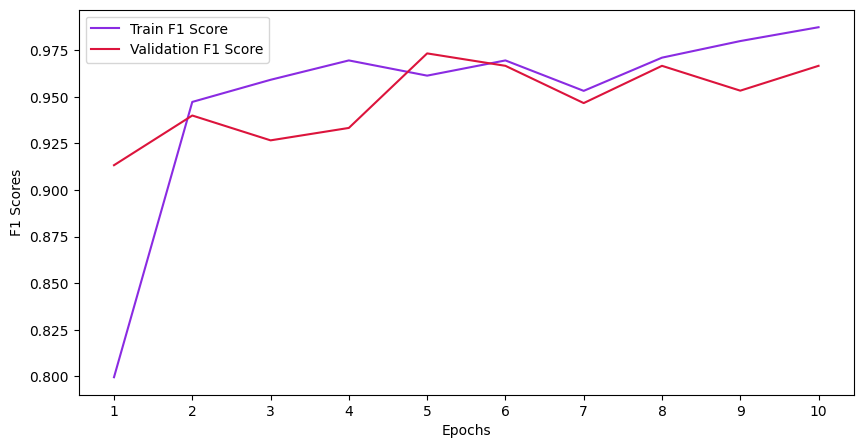

In [6]:
class PlotLearningCurves:
    
    def __init__(self, tr_losses, val_losses, tr_accs, val_accs, tr_f1s, val_f1s):
        
        self.tr_losses, self.val_losses, self.tr_accs, self.val_accs, self.tr_f1s, self.val_f1s = tr_losses, val_losses, tr_accs, val_accs, tr_f1s, val_f1s
        
    def plot(self, array_1, array_2, label_1, label_2, color_1, color_2):
        
        plt.plot(array_1, label = label_1, c = color_1); plt.plot(array_2, label = label_2, c = color_2)
        
    def create_figure(self): plt.figure(figsize = (10, 5))
    
    def decorate(self, ylabel, xlabel = "Epochs"): 
        
        plt.xlabel(xlabel); plt.ylabel(ylabel)
        plt.xticks(ticks = np.arange(len(self.tr_accs)), labels = [i for i in range(1, len(self.tr_accs) + 1)])
        plt.legend(); plt.show()      
        
    def visualize(self):
        
        # Figure 1
        self.create_figure()
        self.plot(array_1 = self.tr_losses, array_2 = self.val_losses, label_1 = "Train Loss", label_2 = "Validation Loss", color_1 = "red", color_2 = "blue"); self.decorate(ylabel = "Loss Values")
        
        # Figure 2
        self.create_figure()
        self.plot(array_1 = self.tr_accs, array_2 = self.val_accs, label_1 = "Train Accuracy", label_2 = "Validation Accuracy", color_1 = "orangered", color_2 = "darkgreen")
        self.decorate(ylabel = "Accuracy Scores")
        
        # Figure 3
        self.create_figure()
        self.plot(array_1 = self.tr_f1s, array_2 = self.val_f1s, label_1 = "Train F1 Score", label_2 = "Validation F1 Score", color_1 = "blueviolet", color_2 = "crimson"); self.decorate(ylabel = "F1 Scores")
        
PlotLearningCurves(tr_losses=trainer.tr_losses, val_losses=trainer.val_losses, tr_accs=trainer.tr_accs, val_accs=trainer.val_accs, tr_f1s=trainer.tr_f1s, val_f1s=trainer.val_f1s).visualize()

<div style='background-color: #fff7f7; border: 2px solid '>
    <font size="+2" color="blue" ><b>✅ 6. Inference and AI Model Performance Analysis with GradCAM ✅</b></font>
</div>

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 50.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.4.6-py3-none-any.whl size=38298 sha256=64f8064a11eb7dbdb5761b960e1d543c9b7496d575000db17f0bfab9525935f2
  Stored in directory: /root/.cache/pip/wheels/3c/6c/04/9a543775e9f25f6c441180a552456f1696167439459730ff87
Successfully built grad-cam


Inference: 496it [00:07, 67.02it/s]


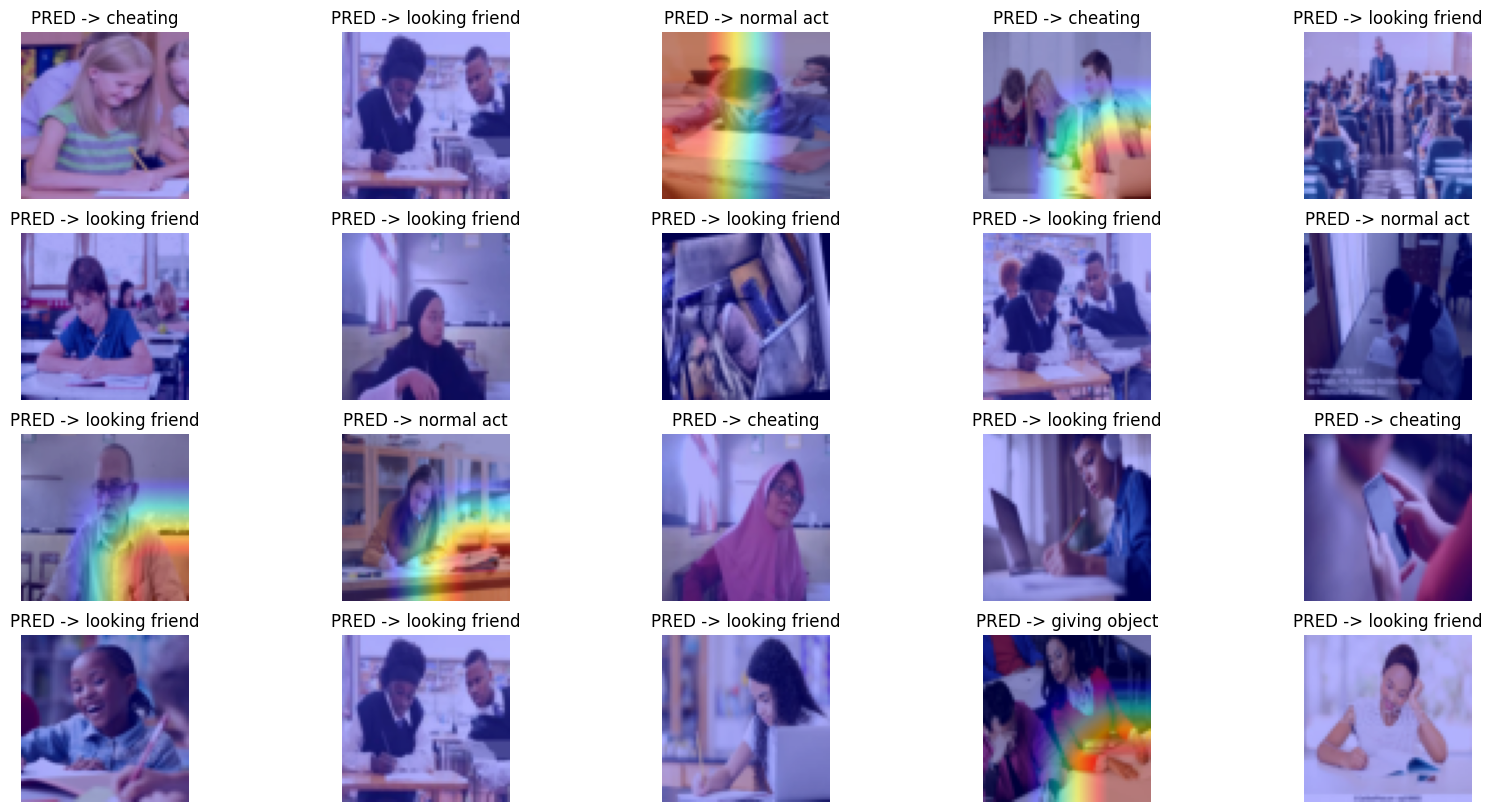

In [7]:
!pip install grad-cam==1.4.6
import cv2
import seaborn as sns
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from sklearn.metrics import confusion_matrix
from tqdm import tqdm

class Denormalize:
    def __init__(self, mean, std):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        """
        Reverse the normalization applied to the image tensor.
        """
        for t, m, s in zip(tensor, self.mean, self.std):
            t.mul_(s).add_(m)
        return tensor

class ModelInferenceVisualizer:
    def __init__(self, model, device, class_names=None, im_size=224, mean = mean, std = std):
        
        self.denormalize = Denormalize(mean, std)
        self.model = model
        self.device = device
        self.class_names = class_names
        self.im_size = im_size
        self.model.eval()  # Set model to evaluation mode

    def tensor_to_image(self, tensor):
        """
        Convert a normalized tensor to a denormalized image array.
        """
        tensor = self.denormalize(tensor)  # Denormalize the tensor
        tensor = tensor.permute(1, 2, 0)  # Convert from CxHxW to HxWxC
        return (tensor.cpu().numpy() * 255).astype(np.uint8)

    def plot_value_array(self, logits, gt, class_names):
        """Plot the prediction probability array."""
        probs = torch.nn.functional.softmax(logits, dim=1)
        pred_class = torch.argmax(probs, dim=1)
        
        plt.grid(visible=True)
        plt.xticks(range(len(class_names)), class_names, rotation='vertical')
        plt.yticks(np.arange(0.0, 1.1, 0.1))
        bars = plt.bar(range(len(class_names)), [p.item() for p in probs[0]], color="#777777")
        plt.ylim([0, 1])
        if pred_class.item() == gt:
            bars[pred_class].set_color('green')
        else:
            bars[pred_class].set_color('red')

    def generate_cam_visualization(self, image_tensor):
        """Generate GradCAM visualization."""
        cam = GradCAMPlusPlus(model=self.model, target_layers=[self.model.features[-1]], use_cuda=self.device == "cuda")
        grayscale_cam = cam(input_tensor=image_tensor.unsqueeze(0))[0, :]
        return grayscale_cam

    def infer_and_visualize(self, test_dl, num_images=5, rows=2):
        """Perform inference and visualize predictions along with GradCAM."""
        preds, images, lbls, logitss = [], [], [], []
        accuracy, count = 0, 1

        with torch.no_grad():
            for idx, batch in tqdm(enumerate(test_dl), desc="Inference"):                
                im = batch[0].to(self.device)                
                logits = self.model(im)
                pred_class = torch.argmax(logits, dim=1)                
                images.append(im[0])
                logitss.append(logits[0])
                preds.append(pred_class[0].item())        

        plt.figure(figsize=(20, 10))
        indices = [random.randint(0, len(images) - 1) for _ in range(num_images)]
        for idx, index in enumerate(indices):
            # Convert and denormalize image
            im = self.tensor_to_image(images[index].squeeze())
            pred_idx = preds[index]           

            # Display image
            plt.subplot(rows, num_images // rows, count)
            count += 1
            plt.imshow(im, cmap="gray")
            plt.axis("off")

            # GradCAM visualization
            grayscale_cam = self.generate_cam_visualization(images[index])
            visualization = show_cam_on_image(im / 255, grayscale_cam, image_weight=0.4, use_rgb=True)
            plt.imshow(cv2.resize(visualization, (self.im_size, self.im_size), interpolation=cv2.INTER_LINEAR), alpha=0.7, cmap='jet')
            plt.axis("off")        

            # Title with GT and Prediction
            if self.class_names:                
                pred_name = self.class_names[pred_idx]                
                plt.title(f"PRED -> {pred_name}")

model = timm.create_model(model_name = model_name, pretrained  = False, num_classes = len(classes)).to(device)
model.load_state_dict(torch.load(f"{save_dir}/{save_prefix}_best_model.pth", weights_only=False))
inference_visualizer = ModelInferenceVisualizer(
    model=model,
    device=device,
    class_names=list(classes.keys()),  # List of class names
    im_size=im_size
)

inference_visualizer.infer_and_visualize(ts_dl, num_images = 20, rows = 4)